# CME538 - Introduction to Data Science

## Assignment 6 - Linear Regression

### Learning Objectives

After completing this assignment, you should be able to:

- Explore relationships between predictors and a continuous target variable using exploratory data analysis.
- Engineer numerical and categorical features for regression.
- Separate training and test data appropriately.
- Fit linear regression models using scikit-learn.
- Evaluate regression models using RMSE and residual analysis.
- Use cross-validation to estimate generalization performance.
- Encode categorical predictors using `OneHotEncoder`.
- Combine preprocessing and modelling using `ColumnTransformer` and `Pipeline`.
- Compare alternative regression models using cross-validation.
- Recognize and avoid common sources of data leakage.
- Build a reproducible regression workflow from feature engineering through final test evaluation.

### Marking Breakdown

| Question | Marks |
|---|---:|
| Question 1a | 1 |
| Question 1b | 1 |
| Question 1c | 1 |
| Question 1d | 1 |
| Question 2a | 1 |
| Question 2b | 1 |
| Question 3a | 1 |
| Question 3b | 1 |
| Question 3c | 1 |
| Question 3d | 1 |
| Question 3e | 1 |
| Question 3f | 1 |
| Question 3g | 1 |
| Question 4 | 1 |
| Question 5a | 1 |
| Question 5b | 1 |
| Question 5c | 1 |
| Question 5d | 1 |
| Question 5e | 2 |
| Question 6a | 1 |
| Question 6b | 2 |
| Question 7 | 3 |
| Question 8 | 1 |
| Code quality | 3 |
| **Total** | **30** |

### Code Quality

Code quality will be assessed across the complete notebook.

| Level | Points | Description |
|---|---:|---|
| **Developing** | 1 | Code produces the required results but may be difficult to follow, unnecessarily repetitive, poorly organized, or include excessive output. |
| **Competent** | 2 | Code is organized and readable, uses appropriate Pandas and scikit-learn operations, and produces concise, relevant outputs. |
| **Strong** | 3 | Code is clear, concise, well organized, and reproducible; uses Pandas and scikit-learn effectively; avoids unnecessary operations and output; and executes successfully from beginning to end. |

## Notebook Setup

In [51]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure notebook plots
%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")

# Overview

In this assignment, we will build a **linear regression model** to predict house sale prices using the **Ames Housing dataset**.

The dataset contains information about residential properties sold in Ames, Iowa, including characteristics such as:

- living area,
- number of bathrooms,
- garage size,
- neighbourhood,
- fireplace quality, and
- sale price.

Our target variable will be `SalePrice`, a continuous numerical variable representing the sale price of each house.

Throughout the assignment, we will use this dataset to develop a complete regression workflow:

1. explore relationships between variables,
2. engineer useful features,
3. build a baseline linear regression model,
4. evaluate its performance,
5. use cross-validation to estimate generalization performance,
6. incorporate categorical predictors using modern scikit-learn preprocessing tools, and
7. improve the model before evaluating it on a held-out test set.

A description of the variables is available in the included `codebook.txt` file. Refer to the codebook as needed throughout the assignment.

---

# 1. Preparing the Ames Housing Data

We will begin by loading the Ames Housing dataset from `ames_data.csv`.

Each row represents a residential property sale, while the columns describe characteristics of the property and the sale.

Before building any models, we will inspect the structure of the dataset and identify the variables that will be useful for our analysis.

In [52]:
# Load the Ames Housing dataset
ames_data = pd.read_csv("ames_data.csv")

# Preview the data
ames_data.head()

,Order,PID,MS_SubClass,MS_Zoning,Lot_Frontage,Lot_Area,Street,Alley,Lot_Shape,Land_Contour,...,Pool_Area,Pool_QC,Fence,Misc_Feature,Misc_Val,Mo_Sold,Yr_Sold,Sale_Type,Sale_Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,204900
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,95300
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,181900
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254100
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,199700


In [53]:
# Inspect the size of the dataset
print(f"Number of observations: {ames_data.shape[0]}")
print(f"Number of variables: {ames_data.shape[1]}")

Number of observations: 2000
Number of variables: 82


The dataset contains both numerical and categorical variables describing different aspects of each property.

Our prediction target is `SalePrice`. Before fitting a regression model, we will use exploratory data analysis to understand its distribution and investigate how it relates to potential predictors.

---
# 2. Exploratory Data Analysis

Before building a regression model, we should understand the variables we are trying to model and identify patterns that may influence our modelling decisions.

We will begin with the target variable, `SalePrice`, and then examine its relationship with potential predictors.

## 2.1 Distribution of Sale Price

`SalePrice` is the variable our regression model will attempt to predict.

Let's examine its distribution using a histogram and a boxplot. Together, these plots help us identify the centre, spread, skewness, and potential extreme values in the target variable.

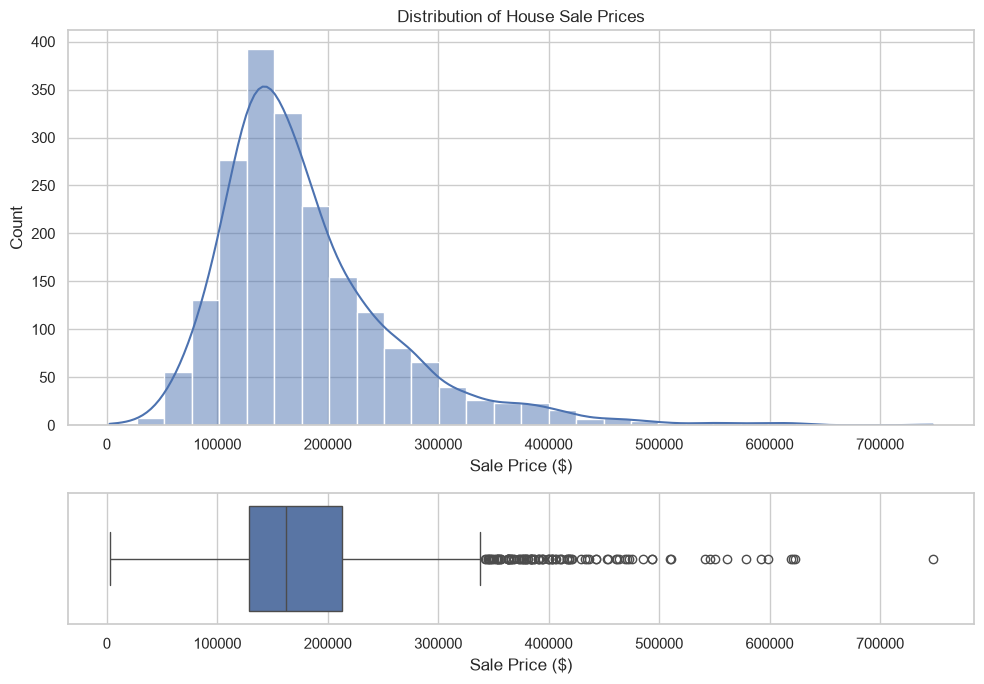

In [54]:
# Visualize the distribution of SalePrice
fig, axes = plt.subplots(
    nrows=2,
    figsize=(10, 7),
    gridspec_kw={"height_ratios": [3, 1]}
)

# Histogram
sns.histplot(
    data=ames_data,
    x="SalePrice",
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of House Sale Prices")
axes[0].set_xlabel("Sale Price ($)")
axes[0].set_ylabel("Count")

# Boxplot
sns.boxplot(
    data=ames_data,
    x="SalePrice",
    ax=axes[1]
)

axes[1].set_xlabel("Sale Price ($)")

plt.tight_layout()
plt.show()

The histogram shows how sale prices are distributed across the dataset, while the boxplot makes it easier to identify unusually high or low values.

We can complement these visualizations with descriptive statistics.

In [55]:
# Summarize SalePrice
ames_data["SalePrice"].describe()

count      2000.000000
mean     180775.897500
std       81581.671741
min        2489.000000
25%      128600.000000
50%      162000.000000
75%      213125.000000
max      747800.000000
Name: SalePrice, dtype: float64

---

## Question 1a — Interpreting the Sale Price Distribution

Based on the visualization and descriptive statistics above, determine whether each statement is **True** or **False**:

1. The distribution of `SalePrice` is right-skewed.
2. The mean `SalePrice` is greater than the median.
3. At least 25% of the houses sold for more than $200,000.

In [56]:
# Question 1a

q1a_1 = True
q1a_2 = True
q1a_3 = True

print(f"1. {q1a_1}")
print(f"2. {q1a_2}")
print(f"3. {q1a_3}")

1. True
2. True
3. True


---

## 2.2 Sale Price and Living Area

One predictor that may help explain house prices is `Gr_Liv_Area`.

According to the codebook, `Gr_Liv_Area` represents the **above-ground living area** of a house, measured in square feet.

Because larger houses generally provide more usable living space, we might expect `Gr_Liv_Area` to be positively associated with `SalePrice`.

Let's examine this relationship.

---

## Question 1b — Visualizing a Predictor

Create a scatterplot with:

- `Gr_Liv_Area` on the x-axis, and
- `SalePrice` on the y-axis.

Include appropriate axis labels and a title.

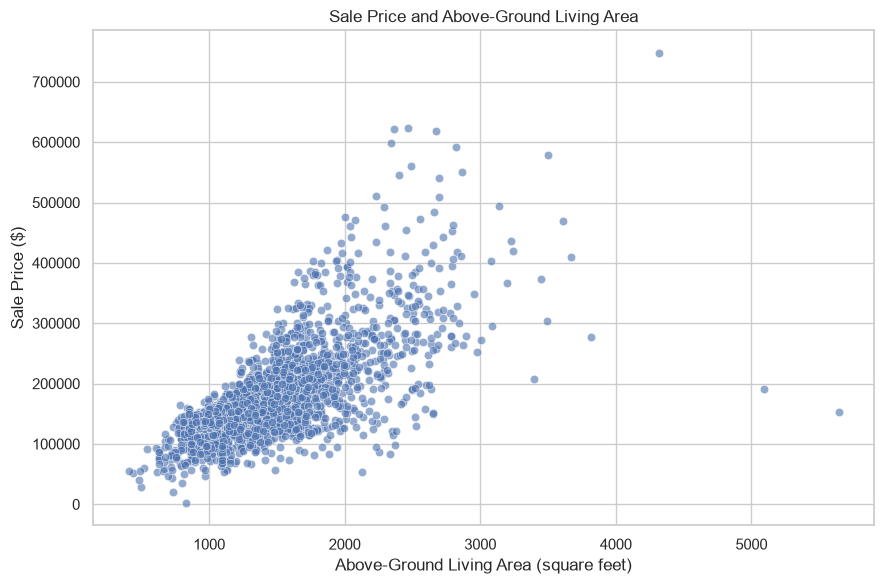

In [57]:
# Question 1b

# Create the requested scatterplot.
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=ames_data,
    x="Gr_Liv_Area",
    y="SalePrice",
    alpha=0.6
)

plt.xlabel("Above-Ground Living Area (square feet)")
plt.ylabel("Sale Price ($)")
plt.title("Sale Price and Above-Ground Living Area")

plt.tight_layout()
plt.show()



The scatterplot shows a clear positive association between living area and sale price: larger houses generally sell for more.

However, a small number of observations have unusually large living areas relative to the rest of the dataset. These observations are worth investigating because unusual observations can strongly influence a fitted linear regression model.

---

## Question 1c — Investigating Unusual Observations

Identify houses with more than **5,000 square feet** of above-ground living area.

Create a DataFrame named `potential_outliers` containing the following columns for these observations:

- `PID`
- `Gr_Liv_Area`
- `SalePrice`

Display the resulting DataFrame.

In [58]:
# Question 1c

potential_outliers = ames_data.loc[
    ames_data["Gr_Liv_Area"] > 5000,
    ["PID", "Gr_Liv_Area", "SalePrice"]
]

potential_outliers

,PID,Gr_Liv_Area,SalePrice
1014,908154235,5642,152200
1471,908154195,5095,190950


---

The observations above correspond to unusually large properties that sold for substantially less than we might expect based on their living area.

For this assignment, observations with `Gr_Liv_Area` greater than or equal to 5,000 square feet will be treated as **known unusual sales**. We will use the fixed rule `Gr_Liv_Area < 5000` when preparing data for model training.

Later, we will create a held-out test set. That test set will not be used to fit models, select features, compare candidate models, or estimate performance during model development.

## Question 1d — Removing Outliers

Create a function named `remove_outliers()` that removes observations outside a specified range for a numerical variable.

The lower and upper limits should be **non-inclusive**. For example,

`remove_outliers(data, "Gr_Liv_Area", upper=5000)`

should return a DataFrame containing only observations where `Gr_Liv_Area` is less than 5,000 square feet.

The function should return a new DataFrame and should not modify the original DataFrame.

In [59]:
# Question 1d

def remove_outliers(data, variable, lower=-np.inf, upper=np.inf):
    """Return observations strictly between lower and upper limits."""
    
    # Write your code here.
    filtered_data = data[
        (data[variable] > lower) &
        (data[variable] < upper)
    ].copy()
    
    return filtered_data

In [60]:
# Verification - do not modify
ames_without_outliers = remove_outliers(
    ames_data,
    "Gr_Liv_Area",
    upper=5000
)

print(f"Q1d Answer - Original observations: {len(ames_data)}")
print(f"Observations after filtering: {len(ames_without_outliers)}")
print(
    "All remaining Gr_Liv_Area values below 5000:",
    (ames_without_outliers["Gr_Liv_Area"] < 5000).all()
)

Q1d Answer - Original observations: 2000
Observations after filtering: 1998
All remaining Gr_Liv_Area values below 5000: True


---
# 3. Feature Engineering

Real-world datasets do not always contain the most useful predictors directly. **Feature engineering** is the process of creating new variables from existing information in a way that may help a model capture meaningful patterns.

In this section, we will create a new feature representing the total number of bathrooms in each house.

## 3.1 Total Bathrooms

The dataset stores full and half bathrooms separately, including bathrooms located in the basement.

We will combine these variables into a single feature:

$$
\text{total\_bathrooms}
=
(\text{Bsmt\_Full\_Bath} + \text{Full\_Bath})
+
0.5(\text{Bsmt\_Half\_Bath} + \text{Half\_Bath})
$$

A full bathroom contributes `1`, while a half bathroom contributes `0.5`.

---

## Question 2a — Create a Total Bathrooms Feature

Write a function named `add_total_bathrooms()` that:

1. creates a copy of the input DataFrame,
2. treats missing bathroom values as `0`,
3. calculates `total_bathrooms` using the formula above, and
4. returns the modified copy.

The original DataFrame should not be modified.

In [61]:
# Question 2a

def add_total_bathrooms(data):
    """Return a copy of data with a total_bathrooms feature."""
    
    # Make a copy of the input DataFrame.
    with_bathrooms = data.copy()
    
    # Define the bathroom columns.
    bathroom_columns = [
        "Bsmt_Full_Bath",
        "Full_Bath",
        "Bsmt_Half_Bath",
        "Half_Bath"
    ]
    
    # Treat missing bathroom values as zero.
    bathrooms = with_bathrooms[bathroom_columns].fillna(0)
    
    # Create total_bathrooms.
    with_bathrooms["total_bathrooms"] = (
        bathrooms["Bsmt_Full_Bath"]
        + bathrooms["Full_Bath"]
        + 0.5 * bathrooms["Bsmt_Half_Bath"]
        + 0.5 * bathrooms["Half_Bath"]
    )
    
    return with_bathrooms

In [62]:
# Add the engineered feature
ames_data_with_bathrooms = add_total_bathrooms(ames_data)

ames_data_with_bathrooms[
    [
        "Bsmt_Full_Bath",
        "Full_Bath",
        "Bsmt_Half_Bath",
        "Half_Bath",
        "total_bathrooms"
    ]
].head()

,Bsmt_Full_Bath,Full_Bath,Bsmt_Half_Bath,Half_Bath,total_bathrooms
0,1.0,1,0.0,0,2.0
1,0.0,1,0.0,0,1.0
2,0.0,1,0.0,1,1.5
3,1.0,2,0.0,1,3.5
4,0.0,2,0.0,1,2.5


In [63]:
# Verification - do not modify
print(
    "Q2a Answer - total_bathrooms created:",
    "total_bathrooms" in ames_data_with_bathrooms.columns
)

print(
    "Missing total_bathrooms values:",
    ames_data_with_bathrooms["total_bathrooms"].isna().sum()
)

print(
    "Original DataFrame unchanged:",
    "total_bathrooms" not in ames_data.columns
)

Q2a Answer - total_bathrooms created: True
Missing total_bathrooms values: 0
Original DataFrame unchanged: True


---

## Question 2b — Total Bathrooms and Sale Price

A useful engineered feature should contain information that may help predict the target variable.

Create a visualization showing the relationship between `total_bathrooms` and `SalePrice`.

Because many houses have the same number of bathrooms, choose a visualization that allows the distributions of sale prices to be compared without excessive overplotting.

Include appropriate axis labels and a title.

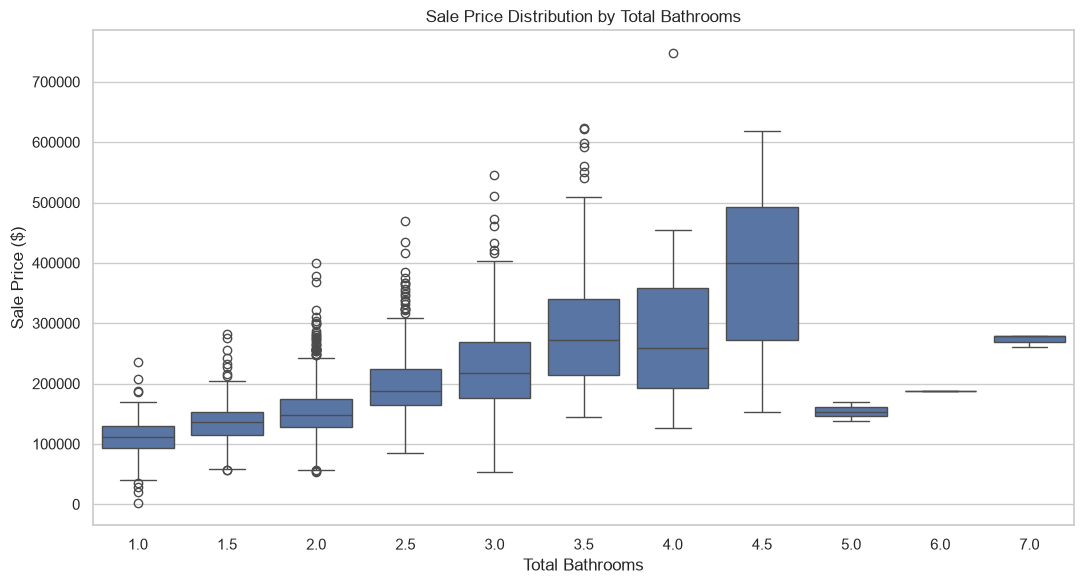

In [64]:
# Question 2b

# Create a visualization showing the relationship between
# total_bathrooms and SalePrice.
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=ames_data_with_bathrooms,
    x="total_bathrooms",
    y="SalePrice"
)

plt.xlabel("Total Bathrooms")
plt.ylabel("Sale Price ($)")
plt.title("Sale Price Distribution by Total Bathrooms")

plt.tight_layout()
plt.show()


In general, houses with more bathrooms tend to have higher sale prices. The relationship is not perfect, but `total_bathrooms` appears to contain useful information for predicting `SalePrice`.

This does not mean that bathrooms alone determine house prices. Rather, the feature may provide additional predictive information when combined with other property characteristics.

---

---
# 4. Building a Baseline Linear Regression Model

We are now ready to move from exploratory analysis to predictive modelling.

Our goal is to build a model that predicts `SalePrice` from several property characteristics.

A key principle in machine learning is that model performance should be evaluated on data that were **not used to fit the model**.

We will therefore separate the dataset into:

- a **training set**, used for model development, feature engineering, and cross-validation, and
- a **test set**, reserved for the final evaluation of the selected model.

The test set will be reserved for final model evaluation. We will not use its target values to fit models, select features, compare candidate models, or make modelling decisions.

---

## Question 3a — Create Training and Test Sets

Split `ames_data` into:

- `train`: 70% of the observations
- `test`: 30% of the observations

Use `train_test_split()` with `random_state=0` so that the split is reproducible.

In [65]:
from sklearn.model_selection import train_test_split

# Question 3a

train, test = train_test_split(
    ames_data,
    test_size=0.30,
    random_state=0
)

In [66]:
# Verification - do not modify
print(f"Q3a Answer - Training observations: {len(train)}")
print(f"Test observations: {len(test)}")

print(
    "Total observations preserved:",
    len(train) + len(test) == len(ames_data)
)

print(
    f"Training proportion: {len(train) / len(ames_data):.2f}"
)
print(
    f"Test proportion: {len(test) / len(ames_data):.2f}"
)

Q3a Answer - Training observations: 1400
Test observations: 600
Total observations preserved: True
Training proportion: 0.70
Test proportion: 0.30


## Preparing Features for the Baseline Model

Our first regression model will use three predictors:

- `Gr_Liv_Area`
- `Garage_Area`
- `total_bathrooms`

Before fitting the model, we need to:

1. remove the known extreme `Gr_Liv_Area` observations,
2. create the `total_bathrooms` feature, and
3. separate the predictors (`X`) from the target (`y`).

We will collect these steps in a reusable function so that the same transformations can be applied consistently during model development.

In [67]:
def prepare_baseline_data(data):
    """Prepare predictors and target for the baseline regression model."""
    
    prepared = remove_outliers(
        data,
        "Gr_Liv_Area",
        upper=5000
    )
    
    prepared = add_total_bathrooms(prepared)
    
    feature_columns = [
        "Gr_Liv_Area",
        "Garage_Area",
        "total_bathrooms"
    ]
    
    X = prepared[feature_columns].copy()
    y = prepared["SalePrice"].copy()
    
    return X, y

In [68]:
# Prepare the training data
X_train, y_train = prepare_baseline_data(train)

print(X_train.shape)
X_train.head()

(1400, 3)


,Gr_Liv_Area,Garage_Area,total_bathrooms
1719,1050,368,2.0
1702,1452,506,3.5
1287,1280,432,2.5
482,1306,472,1.5
768,1677,627,3.5


---

## 4.1 Fitting the Baseline Model

Our first model is:

$$
\widehat{\text{SalePrice}}
=
\beta_0
+
\beta_1(\text{Gr\_Liv\_Area})
+
\beta_2(\text{Garage\_Area})
+
\beta_3(\text{total\_bathrooms})
$$

The model assumes that the predicted sale price can be represented as a linear combination of these predictors.

We will use scikit-learn's `LinearRegression`.

---

## Question 3b — Create the Linear Regression Model

Create a `LinearRegression` object named `linear_model`.

Use the default behaviour of including an intercept.

In [69]:
from sklearn.linear_model import LinearRegression

# Question 3b

linear_model = LinearRegression()

In [70]:
# Verification - do not modify
print(
    "Q3b Answer - Model type:",
    type(linear_model).__name__
)

print(
    "Fit intercept:",
    linear_model.fit_intercept
)

Q3b Answer - Model type: LinearRegression
Fit intercept: True


---

## Question 3c — Fit the Model and Generate Predictions

Fit `linear_model` using `X_train` and `y_train`.

Then create a variable named `y_fitted` containing the model's predictions for the training observations.

In [71]:
# Question 3c

# Fit the model.
linear_model.fit(X_train, y_train)

# Generate fitted values for the training data.
y_fitted = linear_model.predict(X_train)

In [72]:
# Verification - do not modify
print(
    "Q3c Answer - Number of fitted values:",
    len(y_fitted)
)

print(
    "Matches training observations:",
    len(y_fitted) == len(y_train)
)

Q3c Answer - Number of fitted values: 1400
Matches training observations: True


---

## Question 3d — Root Mean Squared Error

The **Root Mean Squared Error (RMSE)** measures the typical magnitude of prediction errors in the same units as the target variable.

For house prices,

$$
\text{RMSE}
=
\sqrt{
\frac{1}{n}
\sum_{i=1}^{n}
(y_i-\hat{y}_i)^2
}
$$

where:

- \(y_i\) is the observed sale price,
- \(\hat{y}_i\) is the predicted sale price, and
- \(n\) is the number of observations.

Write a function named `rmse()` that calculates this quantity without using a loop.

In [73]:
# Question 3d

def rmse(actual, predicted):
    """Calculate root mean squared error."""
    
    # Write your code here.
    return np.sqrt(np.mean((actual - predicted) ** 2))

In [74]:
# Verification - do not modify
example_actual = np.array([100, 200, 300])
example_predicted = np.array([110, 190, 310])

print(
    f"Q3d Answer - Example RMSE: "
    f"{rmse(example_actual, example_predicted):.2f}"
)

Q3d Answer - Example RMSE: 10.00


---

## Question 3e — Evaluate Training Performance

Calculate the RMSE of the baseline model on the training data.

Store the result in `training_rmse`.

In [75]:
# Question 3e

training_rmse = rmse(y_train, y_fitted)

print(f"Training RMSE: ${training_rmse:,.0f}")

Training RMSE: $44,333


---

## Question 3f — Does the Engineered Bathroom Feature Help?

We created `total_bathrooms` because we believed it might contain useful information about house prices.

To test whether it improves prediction, compare:

**Model A**

- `Gr_Liv_Area`
- `Garage_Area`

with:

**Model B**

- `Gr_Liv_Area`
- `Garage_Area`
- `total_bathrooms`

For now, compare their **training RMSE**.

Later, we will use cross-validation to make a more reliable comparison of their generalization performance.

Create a second linear regression model without `total_bathrooms`, fit it, and calculate its training RMSE.

Store the result in `training_rmse_no_bath`.

In [76]:
# Question 3f

# Remove total_bathrooms from the predictors.
X_train_no_bath = X_train.drop(columns=["total_bathrooms"])

# Create the comparison model.
linear_model_no_bath = LinearRegression()


# Fit the model.
linear_model_no_bath.fit(X_train_no_bath, y_train)

# Generate fitted values.
y_fitted_no_bath = linear_model_no_bath.predict(X_train_no_bath)

# Calculate training RMSE.
training_rmse_no_bath = rmse(y_train, y_fitted_no_bath)

print(
    f"Training RMSE with total_bathrooms: "
    f"${training_rmse:,.0f}"
)

print(
    f"Training RMSE without total_bathrooms: "
    f"${training_rmse_no_bath:,.0f}"
)

Training RMSE with total_bathrooms: $44,333
Training RMSE without total_bathrooms: $47,040


---

## 4.2 Residual Analysis

A prediction error for an individual observation is called a **residual**:

$$
\text{residual}
=
\text{actual value}
-
\text{predicted value}
$$

Residual plots help us identify systematic patterns that the model is failing to capture.

For a well-specified regression model, we would generally prefer residuals to be distributed around zero without strong systematic structure.

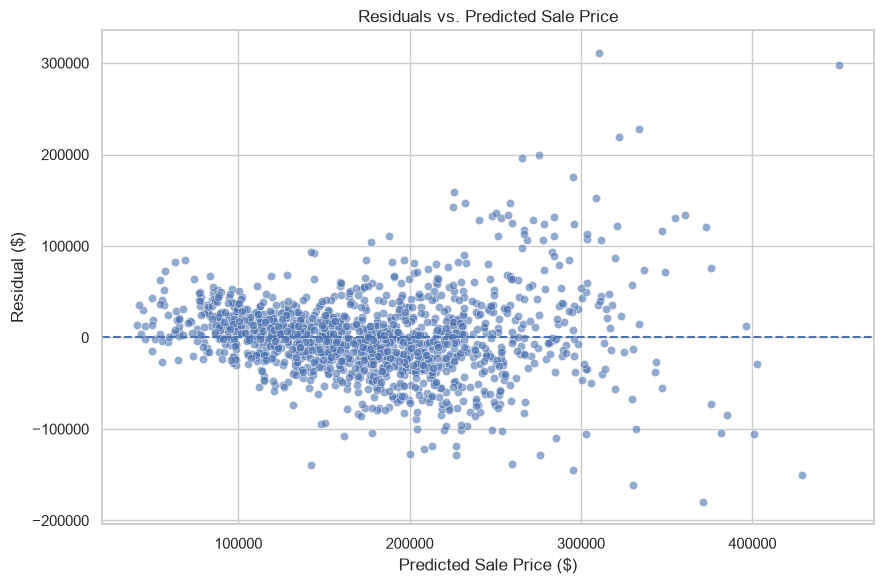

In [77]:
# Calculate training residuals
training_residuals = y_train - y_fitted

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_fitted,
    y=training_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sale Price ($)")
plt.ylabel("Residual ($)")
plt.title("Residuals vs. Predicted Sale Price")

plt.tight_layout()
plt.show()

---

## Question 3g — Interpreting the Baseline Model

Examine the residual plot.

Describe at least **two ways** the current regression model might be improved.

For each suggestion, explain why it could help improve prediction.

Consider ideas such as:

- adding informative predictors,
- representing nonlinear relationships,
- incorporating categorical variables, or
- engineering features from existing variables.

Do not use the test set when proposing or evaluating these changes.

**Your answer:**

*The residuals show that the baseline model does not explain all of the structure in sale prices. First, informative predictors such as overall quality, neighbourhood, and year built could be added because houses with similar living and garage areas can still differ substantially in condition, location, and age. Second, categorical variables such as Neighborhood can be one-hot encoded so that the model can represent location-related price differences without imposing an artificial numerical order. A nonlinear feature, such as a squared living-area term, could also be considered if the residual pattern indicates curvature. These alternatives should be compared using only the training data and cross-validation.*


---
# 5. Cross-Validation and Generalization

Training error tells us how well a model fits the data it has already seen, but it does not tell us how well the model will perform on new observations.

To estimate **generalization performance**, we will use **cross-validation**.

In \(k\)-fold cross-validation:

1. the training data are divided into \(k\) subsets, or folds,
2. the model is trained on \(k-1\) folds,
3. the remaining fold is used for validation,
4. this process is repeated so that every fold is used once for validation.

We will use **5-fold cross-validation**.

The held-out `test` set will remain reserved for final model evaluation and will not be used for model fitting, feature selection, or model comparison.


---

## Question 4 — 5-Fold Cross-Validation

Write a function named `cross_validate_rmse()` that:

- accepts a model, feature matrix `X`, and target `y`,
- performs 5-fold cross-validation,
- fits a fresh copy of the model in each fold,
- calculates the validation RMSE for each fold, and
- returns the five RMSE values.

Use:

- `KFold(n_splits=5, shuffle=True, random_state=0)`, and
- `clone()` to create a fresh estimator for each fold.

In [78]:
from sklearn.model_selection import KFold
from sklearn.base import clone

# Question 4

def cross_validate_rmse(model, X, y):
    """Return validation RMSE values from 5-fold cross-validation."""
    
    # Create the 5-fold splitter
    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=0
    )
    
    rmse_values = []
    
    # Iterate through the cross-validation folds
    for train_index, val_index in kfold.split(X):
        
        # Split the current fold into training and validation data
        X_fold_train = X.iloc[train_index]
        X_fold_val = X.iloc[val_index]
        
        y_fold_train = y.iloc[train_index]
        y_fold_val = y.iloc[val_index]
        
        # Fit a fresh copy of the model
        fold_model = clone(model)
        fold_model.fit(X_fold_train, y_fold_train)
        
        # Predict on the validation fold
        y_fold_predicted = fold_model.predict(X_fold_val)
        
        # Store validation RMSE
        rmse_values.append(rmse(y_fold_val, y_fold_predicted))
    
    return rmse_values

In [79]:
# Verification - do not modify

cv_scores = cross_validate_rmse(
    model=LinearRegression(),
    X=X_train,
    y=y_train
)

print(f"Q4 Answer - Number of folds: {len(cv_scores)}")

print(
    "Cross-validation RMSE scores:",
    [round(score, 0) for score in cv_scores]
)

print(
    f"Mean cross-validation RMSE: "
    f"${np.mean(cv_scores):,.0f}"
)

print(
    f"Standard deviation: "
    f"${np.std(cv_scores):,.0f}"
)

Q4 Answer - Number of folds: 5
Cross-validation RMSE scores: [np.float64(48330.0), np.float64(41335.0), np.float64(41471.0), np.float64(43947.0), np.float64(47421.0)]
Mean cross-validation RMSE: $44,501
Standard deviation: $2,922


The five RMSE values will usually differ because each validation fold contains a different subset of houses.

The **mean cross-validation RMSE** provides a more stable estimate of model performance than evaluating the model using a single validation split.

The **standard deviation** provides additional information about how sensitive the model's performance is to the particular observations included in each fold.

Importantly, the test set has still not been used. It remains reserved for the final evaluation.

## Comparing the Engineered Feature Using Cross-Validation

Earlier, the model containing `total_bathrooms` had a lower training error than the model without it.

However, adding a predictor will often reduce training error even when it does not improve performance on unseen data.

Cross-validation allows us to make a better comparison.

In [80]:
# Cross-validation with total_bathrooms
cv_scores_with_bath = cross_validate_rmse(
    LinearRegression(),
    X_train,
    y_train
)

# Cross-validation without total_bathrooms
cv_scores_no_bath = cross_validate_rmse(
    LinearRegression(),
    X_train_no_bath,
    y_train
)

print(
    f"Mean CV RMSE with total_bathrooms: "
    f"${np.mean(cv_scores_with_bath):,.0f}"
)

print(
    f"Mean CV RMSE without total_bathrooms: "
    f"${np.mean(cv_scores_no_bath):,.0f}"
)

print(
    f"Difference: "
    f"${np.mean(cv_scores_no_bath) - np.mean(cv_scores_with_bath):,.0f}"
)

Mean CV RMSE with total_bathrooms: $44,501
Mean CV RMSE without total_bathrooms: $47,144
Difference: $2,644


---
# 6. Adding Categorical Features

Our baseline model uses only numerical predictors:

- `Gr_Liv_Area`
- `Garage_Area`
- `total_bathrooms`

However, house prices may also depend on characteristics that are represented as **categorical variables**.

Two potentially informative variables are:

- `Neighborhood` — the neighbourhood in which the house is located
- `Fireplace_Qu` — the quality of the fireplace

Categorical variables cannot be passed directly to a standard linear regression model as text values. We therefore need to transform them into numerical features.

Before doing that, we will first explore their relationship with `SalePrice`.

---

## 6.1 Neighbourhood and Sale Price

Location is often an important factor in real-estate prices.

Let's examine whether sale prices vary across the neighbourhoods represented in the **training data**.

To make the figure easier to interpret, the neighbourhoods will be ordered by their median sale price.

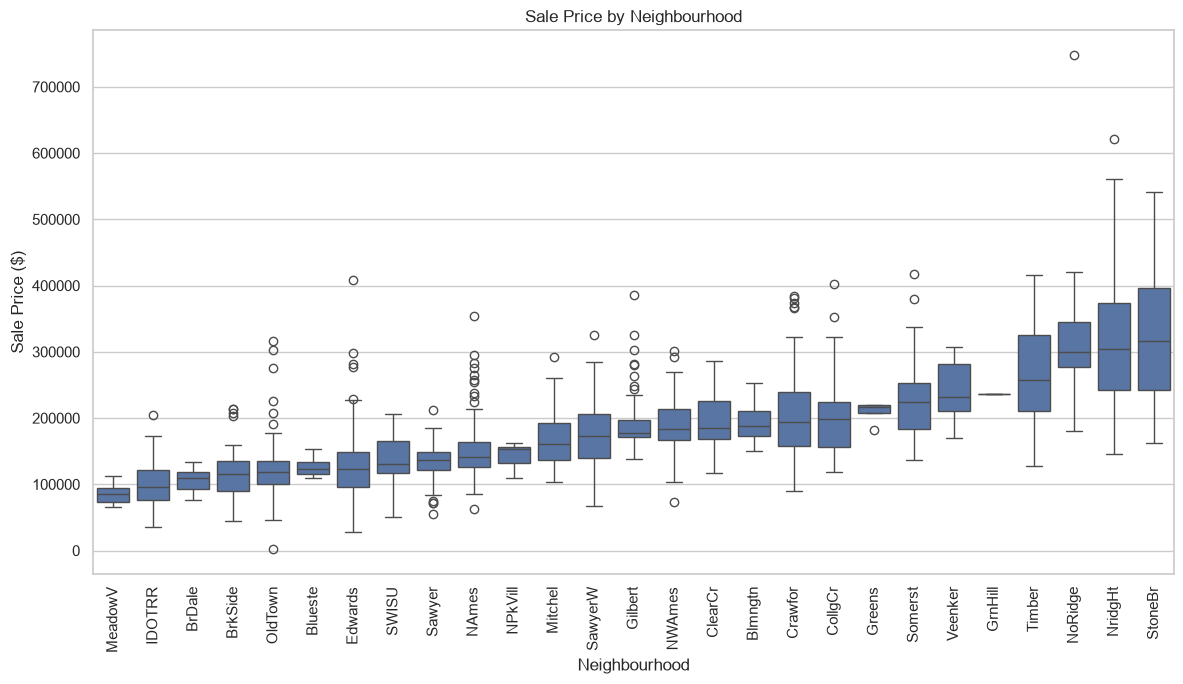

In [81]:
# Order neighbourhoods by median SalePrice in the training data
neighborhood_order = (
    train
    .groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=train,
    x="Neighborhood",
    y="SalePrice",
    order=neighborhood_order
)

plt.xticks(rotation=90)
plt.xlabel("Neighbourhood")
plt.ylabel("Sale Price ($)")
plt.title("Sale Price by Neighbourhood")

plt.tight_layout()
plt.show()

---

## Question 5a — Interpreting Neighbourhood Effects

Based on the visualization above, describe the relationship between `Neighborhood` and `SalePrice`.

In your answer, comment on:

1. whether typical sale prices appear to differ across neighbourhoods, and
2. why `Neighborhood` might provide useful information to a regression model.

**Your answer:**

*Typical sale prices differ substantially across neighbourhoods: the boxplots have different medians and different price ranges. Neighborhood may therefore improve prediction because it can summarize location-related differences such as nearby services, housing characteristics, and local market conditions that are not represented by living area or garage size. This is an association in the training data and does not by itself establish that neighbourhood causes the price differences.*

---

## 6.2 Fireplace Quality

Another potentially useful categorical predictor is `Fireplace_Qu`, which describes fireplace quality.

Before using this variable, we should examine its values and missingness.

In [82]:
# Examine fireplace quality values in the training data
train["Fireplace_Qu"].value_counts(dropna=False)

Fireplace_Qu
NaN    697
Gd     352
TA     275
Fa      34
Ex      23
Po      19
Name: count, dtype: int64

According to the Ames Housing codebook, a missing value in `Fireplace_Qu` does **not** mean that the information was accidentally omitted.

Instead, it indicates that the property has **no fireplace**.

This is an example where understanding the meaning of missing data is important before choosing a preprocessing strategy.

---

## Question 5b — Investigating Missing Fireplace Quality

Calculate:

1. the number of missing values in `Fireplace_Qu`, and
2. the percentage of training observations with a missing `Fireplace_Qu`.

Store the results in:

- `missing_fireplace_count`
- `missing_fireplace_percent`

In [83]:
# Question 5b

missing_fireplace_count = train["Fireplace_Qu"].isna().sum()
missing_fireplace_percent = missing_fireplace_count / len(train) * 100

print(
    f"Missing Fireplace_Qu values: "
    f"{missing_fireplace_count}"
)

print(
    f"Percentage missing: "
    f"{missing_fireplace_percent:.1f}%"
)

Missing Fireplace_Qu values: 697
Percentage missing: 49.8%


In [84]:
# Verification - do not modify
print(
    "Q5b Answer - Count is valid:",
    0 <= missing_fireplace_count <= len(train)
)

print(
    "Percentage is valid:",
    0 <= missing_fireplace_percent <= 100
)

Q5b Answer - Count is valid: True
Percentage is valid: True


---

## Question 5c — Preparing Fireplace Quality

Create a function named `prepare_fireplace_quality()` that:

1. creates a copy of the input DataFrame,
2. replaces missing values in `Fireplace_Qu` with `"No Fireplace"`, and
3. returns the modified DataFrame.

The original DataFrame should remain unchanged.

In [85]:
# Question 5c

def prepare_fireplace_quality(data):
    """Return a copy with missing fireplace quality labelled explicitly."""
    
    # Create a copy of the input DataFrame.
    prepared = data.copy()
    
    # Replace missing Fireplace_Qu values.
    prepared["Fireplace_Qu"] = prepared["Fireplace_Qu"].fillna("No Fireplace")
    
    return prepared

In [86]:
# Verification - do not modify
fireplace_check = prepare_fireplace_quality(train)

print(
    "Q5c Answer - Missing values remaining:",
    fireplace_check["Fireplace_Qu"].isna().sum()
)

print(
    "'No Fireplace' category present:",
    "No Fireplace" in fireplace_check["Fireplace_Qu"].unique()
)

print(
    "Original training data unchanged:",
    train["Fireplace_Qu"].isna().sum() > 0
)

Q5c Answer - Missing values remaining: 0
'No Fireplace' category present: True
Original training data unchanged: True


---

## 6.3 Representing Categorical Variables

A linear regression model requires numerical input.

For a categorical variable such as `Neighborhood`, assigning arbitrary numbers such as

- `Neighborhood A = 1`
- `Neighborhood B = 2`
- `Neighborhood C = 3`

would incorrectly imply a numerical ordering and numerical distance between the categories.

Instead, we will use **one-hot encoding**.

One-hot encoding creates binary indicator columns representing the categories observed in a categorical variable.

For example, a variable containing:

`A`, `B`, and `C`

can be represented using columns such as:

`Neighborhood_A`, `Neighborhood_B`, and `Neighborhood_C`.

Scikit-learn provides `OneHotEncoder` for this transformation.

For an unregularized linear regression model with an intercept, we can use `drop="first"` to omit one category from each categorical feature. The omitted category acts as the reference category for the encoded coefficients.

We will also use `handle_unknown="ignore"` so that the preprocessing workflow can transform new observations containing categories that were not present when the encoder was fitted.

---

## 6.4 Building a Preprocessing Workflow

Our improved model will contain both numerical and categorical predictors.

### Numerical predictors

- `Gr_Liv_Area`
- `Garage_Area`
- `total_bathrooms`

### Categorical predictors

- `Neighborhood`
- `Fireplace_Qu`

The two types of variables require different preprocessing:

- numerical features can be passed directly to the regression model,
- categorical features must be one-hot encoded.

Scikit-learn's `ColumnTransformer` allows us to apply different preprocessing operations to different groups of columns.

---

## Question 5d — Define Numerical and Categorical Features

Create two lists:

- `numeric_features`
- `categorical_features`

containing the variables listed above.

In [87]:
# Question 5d

numeric_features = ["Gr_Liv_Area","Garage_Area","total_bathrooms"]

categorical_features = ["Neighborhood","Fireplace_Qu"]

In [88]:
# Verification - do not modify
print(
    "Q5d Answer - Numerical features:",
    numeric_features
)

print(
    "Categorical features:",
    categorical_features
)

Q5d Answer - Numerical features: ['Gr_Liv_Area', 'Garage_Area', 'total_bathrooms']
Categorical features: ['Neighborhood', 'Fireplace_Qu']


---

In [89]:
# Prepare a working copy of the training data
train_improved = remove_outliers(
    train,
    "Gr_Liv_Area",
    upper=5000
)

train_improved = add_total_bathrooms(
    train_improved
)

train_improved = prepare_fireplace_quality(
    train_improved
)

X_train_improved = train_improved[
    numeric_features + categorical_features
].copy()

y_train_improved = train_improved[
    "SalePrice"
].copy()

X_train_improved.head()

,Gr_Liv_Area,Garage_Area,total_bathrooms,Neighborhood,Fireplace_Qu
1719,1050,368,2.0,NAmes,No Fireplace
1702,1452,506,3.5,Somerst,No Fireplace
1287,1280,432,2.5,NAmes,TA
482,1306,472,1.5,OldTown,No Fireplace
768,1677,627,3.5,SawyerW,No Fireplace


## Question 5e — Create the Preprocessor

Create a `ColumnTransformer` named `preprocessor` that:

- passes the numerical features through unchanged, and
- applies `OneHotEncoder` to the categorical features.

Configure the encoder with:

- `drop="first"`
- `handle_unknown="ignore"`

The `ColumnTransformer` should leave out any columns that are not explicitly included.

In [90]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Question 5e

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

In [91]:
# Verification - do not modify

X_train_transformed = preprocessor.fit_transform(
    X_train_improved
)

print(
    "Q5e Answer - Original feature count:",
    X_train_improved.shape[1]
)

print(
    "Transformed feature count:",
    X_train_transformed.shape[1]
)

print(
    "Number of observations preserved:",
    X_train_transformed.shape[0]
    == X_train_improved.shape[0]
)

Q5e Answer - Original feature count: 5
Transformed feature count: 34
Number of observations preserved: True


In [92]:
# Inspect the names of the transformed predictors
transformed_feature_names = (
    preprocessor.get_feature_names_out()
)

transformed_feature_names[:15]

array(['numeric__Gr_Liv_Area', 'numeric__Garage_Area',
       'numeric__total_bathrooms', 'categorical__Neighborhood_Blueste',
       'categorical__Neighborhood_BrDale',
       'categorical__Neighborhood_BrkSide',
       'categorical__Neighborhood_ClearCr',
       'categorical__Neighborhood_CollgCr',
       'categorical__Neighborhood_Crawfor',
       'categorical__Neighborhood_Edwards',
       'categorical__Neighborhood_Gilbert',
       'categorical__Neighborhood_Greens',
       'categorical__Neighborhood_GrnHill',
       'categorical__Neighborhood_IDOTRR',
       'categorical__Neighborhood_MeadowV'], dtype=object)

Notice that the preprocessing step expands the categorical variables into several numerical indicator columns.

This preprocessing object has an important advantage over manually calling `pd.get_dummies()`: it can be **fitted on training data and then reused consistently on new data**.

In the next section, we will combine this preprocessing step with `LinearRegression` in a single scikit-learn `Pipeline`.

---
# 7. Building an Improved Regression Pipeline

Our baseline model used only three numerical predictors.

We have now identified two categorical variables that may contain additional information about house prices:

- `Neighborhood`
- `Fireplace_Qu`

Rather than preprocessing these variables manually and then fitting a model separately, we will combine the preprocessing and regression steps into a single **scikit-learn Pipeline**.

A pipeline provides a reproducible modelling workflow in which:

1. the appropriate preprocessing is applied to each feature,
2. the transformed features are passed to the model, and
3. the entire workflow can be fitted, cross-validated, and used for prediction as one object.

This is especially important during cross-validation because preprocessing should be learned from each training fold rather than from the corresponding validation fold.

---

## Question 6a — Create the Regression Pipeline

Create a scikit-learn `Pipeline` named `improved_model` containing:

1. the `preprocessor` created in Question 5e, and
2. a `LinearRegression` model.

Name the two pipeline steps:

- `"preprocessor"`
- `"regression"`

In [93]:
from sklearn.pipeline import Pipeline

# Question 6a

improved_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regression", LinearRegression())
    ]
)

improved_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, 

In [94]:
# Verification - do not modify
print(
    "Q6a Answer - Object type:",
    type(improved_model).__name__
)

print(
    "Pipeline steps:",
    list(improved_model.named_steps.keys())
)

print(
    "Final estimator:",
    type(improved_model.named_steps["regression"]).__name__
)

Q6a Answer - Object type: Pipeline
Pipeline steps: ['preprocessor', 'regression']
Final estimator: LinearRegression


---

## Question 6b — Evaluate the Improved Model

Use `cross_validate_rmse()` to evaluate `improved_model` using the training data.

Store the five RMSE values in `cv_scores_improved`.

Then compare the mean cross-validation RMSE of:

- the baseline model, and
- the improved model containing numerical and categorical predictors.

Remember that `X_train_improved` contains the predictors needed by the new pipeline.

In [95]:
# Question 6b

cv_scores_improved = cross_validate_rmse(
    improved_model,
    X_train_improved,
    y_train_improved
)

baseline_cv_rmse = np.mean(cv_scores)
improved_cv_rmse = np.mean(cv_scores_improved)

cv_improvement = baseline_cv_rmse - improved_cv_rmse

print(
    "Improved-model CV RMSE scores:",
    [round(score) for score in cv_scores_improved]
)

print(
    f"\nBaseline mean CV RMSE: "
    f"${baseline_cv_rmse:,.0f}"
)

print(
    f"Improved mean CV RMSE: "
    f"${improved_cv_rmse:,.0f}"
)

print(
    f"Reduction in mean CV RMSE: "
    f"${cv_improvement:,.0f}"
)

Improved-model CV RMSE scores: [38761, 36915, 33193, 33296, 38699]

Baseline mean CV RMSE: $44,501
Improved mean CV RMSE: $36,173
Reduction in mean CV RMSE: $8,328


C:\anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [96]:
# Verification - do not modify
print(
    "Q6b Answer - Five CV scores:",
    len(cv_scores_improved) == 5
)

print(
    "Improved model has lower mean CV RMSE:",
    improved_cv_rmse < baseline_cv_rmse
)

Q6b Answer - Five CV scores: True
Improved model has lower mean CV RMSE: True


The improved model can now use differences among neighbourhoods and fireplace-quality categories in addition to the numerical property characteristics used by the baseline model.

The important comparison is the **cross-validation error**, not the training error. A lower cross-validation RMSE provides evidence that the additional features improve the model's expected performance on unseen observations.

The held-out test set has not been used for model fitting, model comparison, or performance evaluation.

---
# 8. Improving the Model

So far, our improved model uses:

### Numerical features

- `Gr_Liv_Area`
- `Garage_Area`
- `total_bathrooms`

### Categorical features

- `Neighborhood`
- `Fireplace_Qu`

However, the Ames dataset contains many additional property characteristics that may help explain variation in sale price.

Your final model-development task is to investigate whether additional features can improve the model's **cross-validation performance**.

You may use the codebook and exploratory analysis to identify potentially informative predictors.

Do **not** use the test set while developing or comparing models.

---

## Question 7 — Improve the Regression Model

Develop an alternative linear regression model by adding at least **one additional predictor or engineered feature** beyond those used in `improved_model`.

Your goal is to investigate whether the additional information improves cross-validation performance.

For your proposed improvement:

1. identify the feature or features you added,
2. explain why you expect them to help predict `SalePrice`,
3. include appropriate exploratory analysis to support your choice,
4. incorporate the new features into a `ColumnTransformer` and `Pipeline`, and
5. evaluate the model using the same 5-fold cross-validation procedure.

Your work should create the following variables:

- `final_model` — your final regression pipeline,
- `X_train_final` — the predictors used to train the final model,
- `y_train_final` — the corresponding training target,
- `cv_scores_final` — the five cross-validation RMSE values, and
- `final_cv_rmse` — the mean of those five RMSE values.

Your goal is not simply to add as many features as possible. Prefer features that you can justify based on the data and the problem context.

Use Markdown cells to explain your feature-selection or feature-engineering decisions.

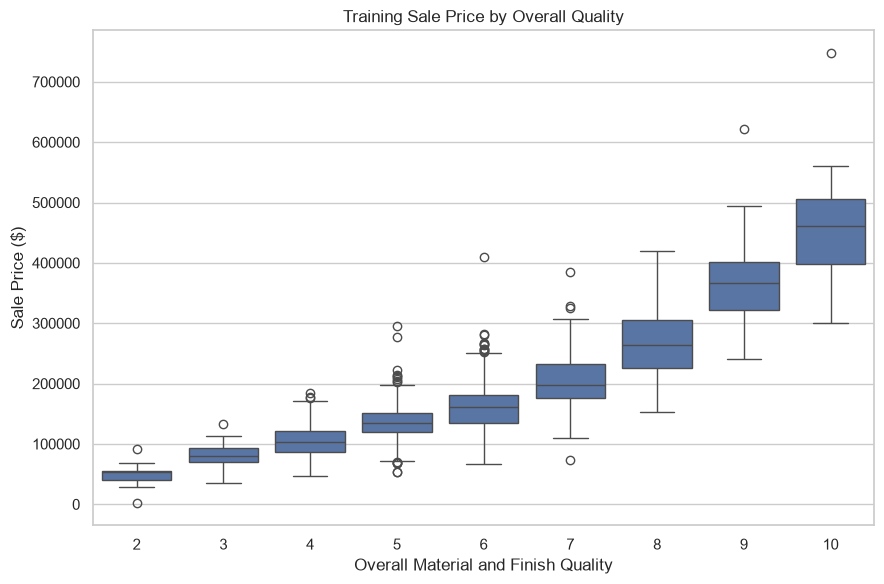

Final-model CV RMSE scores: [36065, 33718, 28830, 30132, 34207]
Improved-model mean CV RMSE: $36,173
Final-model mean CV RMSE: $32,590
Reduction after adding Overall_Qual: $3,582


C:\anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [47]:
# Question 7

# Add as many Markdown and code cells as needed.
#
# Your final solution should create:
#
#   final_model
#   X_train_final
#   y_train_final
#   cv_scores_final
#   final_cv_rmse
#
# Include at least one additional predictor or engineered feature
# beyond those used in improved_model.

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=train_improved,
    x="Overall_Qual",
    y="SalePrice"
)

plt.xlabel("Overall Material and Finish Quality")
plt.ylabel("Sale Price ($)")
plt.title("Training Sale Price by Overall Quality")

plt.tight_layout()
plt.show()

# Add Overall_Qual to the numerical predictors.
numeric_features_final = numeric_features + ["Overall_Qual"]

final_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            numeric_features_final
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

final_model = Pipeline(
    steps=[
        ("preprocessor", final_preprocessor),
        ("regression", LinearRegression())
    ]
)

X_train_final = train_improved[
    numeric_features_final + categorical_features
].copy()

y_train_final = y_train_improved.copy()

cv_scores_final = cross_validate_rmse(
    final_model,
    X_train_final,
    y_train_final
)

final_cv_rmse = np.mean(cv_scores_final)

print(
    "Final-model CV RMSE scores:",
    [round(score) for score in cv_scores_final]
)

print(f"Improved-model mean CV RMSE: ${improved_cv_rmse:,.0f}")
print(f"Final-model mean CV RMSE: ${final_cv_rmse:,.0f}")
print(
    f"Reduction after adding Overall_Qual: "
    f"${improved_cv_rmse - final_cv_rmse:,.0f}"
)

In [48]:
# Verification - do not modify
print(
    "Five CV scores produced:",
    len(cv_scores_final) == 5
)

print(
    f"Improved-model mean CV RMSE: "
    f"${improved_cv_rmse:,.0f}"
)

print(
    f"Final-model mean CV RMSE: "
    f"${final_cv_rmse:,.0f}"
)

Five CV scores produced: True
Improved-model mean CV RMSE: $36,173
Final-model mean CV RMSE: $32,590


---
# 9. Final Evaluation on the Test Set

Model development is now complete.

We used the training data and cross-validation to:

- select predictors,
- engineer features,
- compare model specifications, and
- choose our final regression pipeline.

Only now will we evaluate the selected model on the held-out test set.

The test RMSE provides our final estimate of how the selected modelling workflow performs on previously unseen observations.

---

## Question 8 — Evaluate the Final Model

Prepare the held-out `test` data using the same deterministic feature-engineering steps used for the final training data.

Then:

1. create `X_test` and `y_test`,
2. fit `final_model` using **all of `X_train_final` and `y_train_final`**,
3. predict the sale prices for `X_test`,
4. store the predictions in `y_test_predicted`, and
5. calculate the test RMSE and store it in `test_rmse`.

Do not make further changes to the model after examining the test-set result.

In [49]:
# Question 8

# Apply the deterministic feature-engineering steps
# used by your final model.
final_test_data = add_total_bathrooms(test)
final_test_data = prepare_fireplace_quality(final_test_data)


# Select the test predictors.
X_test = final_test_data[
    numeric_features_final + categorical_features
].copy()

# Select the test target.
y_test = final_test_data["SalePrice"].copy()

# Fit the selected final model using all training data.
final_model.fit(X_train_final, y_train_final)

# Predict the held-out test set.
y_test_predicted = final_model.predict(X_test)

# Calculate final test RMSE.
test_rmse = rmse(y_test, y_test_predicted)

print(
    f"Final cross-validation RMSE: "
    f"${final_cv_rmse:,.0f}"
)

print(
    f"Final test RMSE: "
    f"${test_rmse:,.0f}"
)

Final cross-validation RMSE: $32,590
Final test RMSE: $42,503


In [50]:
# Verification - do not modify
print(
    "Q8 Answer - All test observations retained:",
    len(y_test) == len(test)
)

print(
    "Predictions match test observations:",
    len(y_test_predicted) == len(y_test)
)

print(
    "Test RMSE is positive:",
    test_rmse > 0
)

Q8 Answer - All test observations retained: True
Predictions match test observations: True
Test RMSE is positive: True


---
# Submission

Before submitting your assignment:

1. Restart the kernel and run all cells from beginning to end.
2. Make sure all code cells execute without errors.
3. Review your answers and remove unnecessary scratch cells or output.
4. Save your completed notebook (`.ipynb`).
5. Export the notebook as an HTML file (`.html`).
6. Submit both files to Quercus.
